In [ ]:
from pathlib import Path
import re
import numpy as np
import rasterio
from rasterio.transform import from_bounds
from rasterio.enums import ColorInterp
from rasterio.warp import reproject, Resampling
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import sataid

# =========================================================
# SETTINGS
# =========================================================
DATA_DIR = Path(r"D:\Experiment Ajarn\dotz\Lewotobi")

# extent target
LAT_MIN = -10.8
LAT_MAX = -6.2
LON_MIN = 119.0
LON_MAX = 123.65

# output size
OUT_WIDTH = 256
OUT_HEIGHT = 256

SAVE_AS_UINT8 = True
CONVERT_TO_KELVIN = True
# =========================================================


def normalize(arr, vmin, vmax, gamma=1.0, invert=False):
    arr = (arr - vmin) / (vmax - vmin)
    arr = np.clip(arr, 0, 1)
    if invert:
        arr = 1.0 - arr
    if gamma != 1.0:
        arr = arr ** (1.0 / gamma)
    return arr


def parse_file_info(path: Path):
    m = re.match(r"H09_(B\d{2})_Indonesia_(\d{8})\.Z(\d{4})$", path.name, re.IGNORECASE)
    if not m:
        return None
    band, date_str, time_str = m.groups()
    return {
        "band": band.upper(),
        "date": date_str,
        "time": time_str,
        "key": f"{date_str}_{time_str}"
    }


def build_file_groups(data_dir: Path):
    groups = {}
    for f in data_dir.iterdir():
        if not f.is_file():
            continue
        info = parse_file_info(f)
        if info is None:
            continue
        key = info["key"]
        band = info["band"]
        groups.setdefault(key, {})[band] = f
    return groups


def read_band_kelvin(path: Path):
    sat = sataid.read_sataid(str(path))

    lat = np.asarray(sat.lat)
    lon = np.asarray(sat.lon)
    data = np.asarray(sat.data, dtype=np.float32)

    if CONVERT_TO_KELVIN:
        data = data + 273.15

    return lat, lon, data


def make_ash_rgb_kelvin(b11, b13, b15):
    # Ash RGB standard
    red_raw = b15 - b13
    green_raw = b13 - b11
    blue_raw = b13/1

    red = normalize(red_raw, -4.0, 2.0, gamma=1.0, invert=False)
    green = normalize(green_raw, -4.0, 5.0, gamma=1.2, invert=False)
    blue = normalize(blue_raw, 243.6, 303.2, gamma=1.0, invert=False)

    rgb = np.dstack([red, green, blue])
    return rgb


def get_source_transform(lon, lat, width, height):
    west = float(np.min(lon))
    east = float(np.max(lon))
    south = float(np.min(lat))
    north = float(np.max(lat))
    return from_bounds(west, south, east, north, width, height)


def crop_and_resample_rgb(rgb, lon, lat,
                          lon_min=LON_MIN, lon_max=LON_MAX,
                          lat_min=LAT_MIN, lat_max=LAT_MAX,
                          out_width=OUT_WIDTH, out_height=OUT_HEIGHT):
    """
    Crop + resample RGB ke extent target dan ukuran target.
    """
    src_h, src_w, _ = rgb.shape

    src_transform = get_source_transform(lon, lat, src_w, src_h)
    dst_transform = from_bounds(lon_min, lat_min, lon_max, lat_max, out_width, out_height)

    dst_rgb = np.zeros((out_height, out_width, 3), dtype=np.float32)

    for i in range(3):
        reproject(
            source=rgb[:, :, i],
            destination=dst_rgb[:, :, i],
            src_transform=src_transform,
            src_crs="EPSG:4326",
            dst_transform=dst_transform,
            dst_crs="EPSG:4326",
            resampling=Resampling.bilinear
        )

    dst_rgb = np.clip(dst_rgb, 0, 1)
    return dst_rgb, dst_transform


def write_rgb_geotiff(out_path: Path, rgb, transform):
    h, w, _ = rgb.shape

    if SAVE_AS_UINT8:
        rgb_out = (rgb * 255).astype(np.uint8)
        dtype = rasterio.uint8
    else:
        rgb_out = rgb.astype(np.float32)
        dtype = rasterio.float32

    with rasterio.open(
        out_path,
        "w",
        driver="GTiff",
        height=h,
        width=w,
        count=3,
        dtype=dtype,
        crs="EPSG:4326",
        transform=transform
    ) as dst:
        dst.write(rgb_out[:, :, 0], 1)
        dst.write(rgb_out[:, :, 1], 2)
        dst.write(rgb_out[:, :, 2], 3)
        dst.colorinterp = (
            ColorInterp.red,
            ColorInterp.green,
            ColorInterp.blue
        )


def save_visual_tiff(out_path: Path, rgb, key):
    """
    Simpan TIFF visualisasi dengan grid 1 derajat + coastline/pulau.
    """
    fig = plt.figure(figsize=(8, 8), dpi=200)
    ax = plt.axes(projection=ccrs.PlateCarree())

    ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=ccrs.PlateCarree())

    ax.imshow(
        rgb,
        origin="upper",
        extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
        transform=ccrs.PlateCarree()
    )

    # coastline / pulau
    ax.coastlines(resolution="10m", linewidth=0.6, color="lime")
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor="gray")

    # grid 1 derajat
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.5,
        color="white",
        alpha=0.6,
        linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = plt.FixedLocator(np.arange(np.floor(LON_MIN), np.ceil(LON_MAX) + 1, 1))
    gl.ylocator = plt.FixedLocator(np.arange(np.floor(LAT_MIN), np.ceil(LAT_MAX) + 1, 1))

    ax.set_title(f"Ash RGB {key}")

    plt.savefig(out_path, dpi=200, bbox_inches="tight", format="tiff")
    plt.close(fig)


def main():
    if not DATA_DIR.exists():
        print(f"[ERROR] Folder tidak ditemukan: {DATA_DIR}")
        return

    groups = build_file_groups(DATA_DIR)

    if not groups:
        print("[ERROR] Tidak ada file Himawari yang cocok dengan pola nama.")
        return

    print(f"Jumlah waktu terdeteksi: {len(groups)}")

    for key in sorted(groups.keys()):
        group = groups[key]

        if not all(b in group for b in ["B11", "B13", "B15"]):
            print(f"[SKIP] {key}: band belum lengkap")
            continue

        print(f"\n[INFO] Processing {key}")

        f11 = group["B11"]
        f13 = group["B13"]
        f15 = group["B15"]

        try:
            lat11, lon11, b11 = read_band_kelvin(f11)
            lat13, lon13, b13 = read_band_kelvin(f13)
            lat15, lon15, b15 = read_band_kelvin(f15)

            if b11.shape != b13.shape or b11.shape != b15.shape:
                print(f"[SKIP] {key}: dimensi band tidak sama")
                continue

            rgb = make_ash_rgb_kelvin(b11, b13, b15)

            # crop + resample ke 256x256
            rgb_crop, dst_transform = crop_and_resample_rgb(
                rgb, lon11, lat11,
                lon_min=LON_MIN, lon_max=LON_MAX,
                lat_min=LAT_MIN, lat_max=LAT_MAX,
                out_width=OUT_WIDTH, out_height=OUT_HEIGHT
            )

 # GeoTIFF murni
            out_geotiff = DATA_DIR / f"AshRGB_Lewotobi_{key}.tif"
            write_rgb_geotiff(out_geotiff, rgb_crop, dst_transform)
            print(f"[OK] Saved GeoTIFF: {out_geotiff.name}")

            # TIFF visualisasi dengan grid + pulau
            out_vis_tiff = DATA_DIR / f"AshRGB_Lewotobi_{key}_grid.tif"
            save_visual_tiff(out_vis_tiff, rgb_crop, key)
            print(f"[OK] Saved Map TIFF: {out_vis_tiff.name}")

        except Exception as e:
            print(f"[ERROR] Gagal pada {key}: {e}")


if __name__ == "__main__":
    main()

Jumlah waktu terdeteksi: 58

[INFO] Processing 20241108_2030
[OK] Saved GeoTIFF: AshRGB_Lewotobi_20241108_2030.tif
[OK] Saved Map TIFF: AshRGB_Lewotobi_20241108_2030_grid.tif

[INFO] Processing 20241108_2100
[OK] Saved GeoTIFF: AshRGB_Lewotobi_20241108_2100.tif
[OK] Saved Map TIFF: AshRGB_Lewotobi_20241108_2100_grid.tif

[INFO] Processing 20241108_2130
[OK] Saved GeoTIFF: AshRGB_Lewotobi_20241108_2130.tif
[OK] Saved Map TIFF: AshRGB_Lewotobi_20241108_2130_grid.tif

[INFO] Processing 20241108_2200
[OK] Saved GeoTIFF: AshRGB_Lewotobi_20241108_2200.tif
[OK] Saved Map TIFF: AshRGB_Lewotobi_20241108_2200_grid.tif

[INFO] Processing 20241108_2230
[OK] Saved GeoTIFF: AshRGB_Lewotobi_20241108_2230.tif
[OK] Saved Map TIFF: AshRGB_Lewotobi_20241108_2230_grid.tif

[INFO] Processing 20241108_2300
[OK] Saved GeoTIFF: AshRGB_Lewotobi_20241108_2300.tif
[OK] Saved Map TIFF: AshRGB_Lewotobi_20241108_2300_grid.tif

[INFO] Processing 20241108_2330
[OK] Saved GeoTIFF: AshRGB_Lewotobi_20241108_2330.tif
[OK

C:\Users\computer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)
C:\Users\computer\AppData\Local\Temp\ipykernel_20704\1146802195.py:8: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  r = src.read(1)
C:\Users\computer\AppData\Local\Temp\ipykernel_20704\1146802195.py:9: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  g = src.read(2)
C:\Users\computer\AppData\Local\Temp\ipykernel_20704\1146802195.py:10: DeprecationWarning:

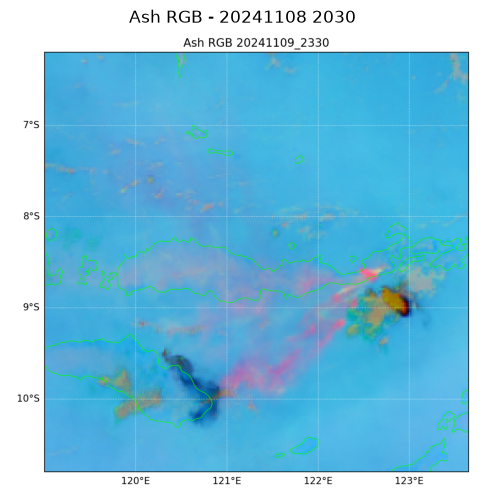

In [10]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

tif_path = r"D:\Data Satelit\9 Nov 2024\AshRGB_Lewotobi_20241109_2330_grid.tif"

with rasterio.open(tif_path) as src:
    r = src.read(1)
    g = src.read(2)
    b = src.read(3)

# gabungkan jadi RGB
rgb = np.dstack([r, g, b])

# kalau datanya uint8 (0-255), ubah ke 0-1 untuk plot yang bagus
if rgb.dtype == np.uint8:
    rgb_plot = rgb / 255.0
else:
    rgb_plot = np.clip(rgb, 0, 1)

plt.figure(figsize=(10, 6))
plt.imshow(rgb_plot)
plt.title("Ash RGB - 20241108 2030")
plt.axis("off")
plt.show()